# Appendix C — The Vaccinated Compartment V vs the Real Data (Delta Wave)

**Built 2026-08-06.** The Delta-wave SEIRV model (notebook 08 §8.14,
formulae_sheet §6) tracks a vaccinated compartment V:

$$\frac{dV_{ik}}{dt} = v_i(t)\,\frac{S_{ik}}{N_i} - w\,V_{ik}$$

with $V_0$ = cumulative fully-vaccinated at 2021-05-31 and $v_i(t)$ = the
monthly fully-vaccinated flow (people/day) from the CDC data. Two features
of this equation are worth checking against reality:

1. **The flow is scaled by the susceptible share** $S/N$ — in the model,
   only susceptibles get vaccinated. The real CDC series counts *all* newly
   fully-vaccinated people.  With $S/N \approx 0.34$ at the window start,
   the model's V should grow roughly three times slower than the raw data.
2. **$V_0$ uses the full cumulative count** (efficacy ε = 1), so the two
   series coincide at the window start by construction and diverge through
   the window.

This appendix makes that comparison explicit, per state, and then asks:
**does the in-window vaccination detail matter for the epidemic fit?**

| Section | Content |
|---|---|
| §C.1 | the model's V dynamics vs the CDC series (national) |
| §C.2 | per-state comparison |
| §C.3 | sensitivity: how much the epidemic fit depends on the vaccination flow |
| §C.4 | honest reading |

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, '../src')
from fused_metapopulation import (
    JURISDICTIONS, CENSUS_POPULATIONS, CODE_TO_NAME, NAME_TO_CODE,
    T_MO, build_distance_matrix, build_gravity_kernel, fit_gravity_exponents,
    calibrate_mobility, s_interpolator, truncated_power_law,
    power_law_alpha_for_mean_k, FusedMetapopulationSEIR,
)
from data_loader import load_us_states

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})
ASSETS = '../assets'
DAY0 = pd.Timestamp('2020-01-01')
sigma, gamma = 1.0 / 5, 1.0 / 10
T0 = (pd.Timestamp('2021-06-01') - DAY0).days
TMAX = (pd.Timestamp('2021-10-31') - DAY0).days

def show_fig(path):
    from IPython.display import Image, display
    display(Image(filename=path))

us = load_us_states()
vax = pd.read_csv('../data/cdc_vax_state_monthly.csv')
print('data ready')

data ready


## §C.1 The model's V vs the CDC series (national)

Build the standard Delta SEIRV run (the §8.14 pipeline: β from the Jul–Aug
growth slopes, π₀ = 0.15, prior immunity asc = 3, two-regime ρ = 0.9) and
extract the national V = Σ states.  Compare with the CDC cumulative
fully-vaccinated series over the window, and with the *flow* into V:
model $v(t)\cdot S(t)/N$ vs the raw $v(t)$.

In [2]:
# --- the standard Delta pipeline (as in notebook 08 §8.14 / nb06 Step 7) ---
alpha = power_law_alpha_for_mean_k(6.0)
k_vals, P_k = truncated_power_law(alpha=alpha)
mean_k = float(k_vals @ P_k); mean_k2 = float((k_vals ** 2) @ P_k)
mom_ratio = mean_k2 / mean_k

win_start = pd.Timestamp('2021-07-01'); win_days = 62
rs, bs = {}, {}
for code in JURISDICTIONS:
    sub = us[(us.state == CODE_TO_NAME[code]) & (us.date >= win_start)
             & (us.date < win_start + pd.Timedelta(days=win_days))]
    v = sub['new_cases_smooth'].values; t = np.arange(len(v)); m = v > 0
    rv = np.nan
    if m.sum() >= 5:
        sl = np.polyfit(t[m], np.log(v[m]), 1)[0]
        if sl > 0: rv = sl
    rs[code] = rv
    bs[code] = (rv + gamma) * (rv + sigma) / sigma / mom_ratio if not np.isnan(rv) else np.nan
bs = pd.Series(bs).fillna(pd.Series(bs).median()).clip(upper=6.0 * gamma / mom_ratio)
rs = pd.Series(rs).fillna(float(pd.Series(rs).median()))

pi0 = 0.15
I0, E0 = {}, {}
for code in JURISDICTIONS:
    row = us[(us.state == CODE_TO_NAME[code]) & (us.date == pd.Timestamp('2021-06-01'))]
    i0 = float(row['new_cases'].iloc[0]) if len(row) else 0.0
    I0[code] = i0 / pi0
    E0[code] = I0[code] * (rs[code] + gamma) / sigma

months_full = [(y, m) for y in range(2020, 2024) for m in range(1, 13)][:39]
gidx = [f'{y:04d}-{m:02d}' for y, m in months_full]
pv = vax.pivot_table(index='state', columns='month', values='series_complete_flow') \
     .reindex(index=JURISDICTIONS, columns=gidx).fillna(0)
cumv = vax.pivot_table(index='state', columns='month', values='series_complete') \
       .reindex(index=JURISDICTIONS, columns=gidx).fillna(0)
flow = pv.values / T_MO                     # people/day into V (raw data)
eps, asc = 1.0, 3.0
V0 = {s: float(cumv.loc[s, '2021-05']) * eps for s in JURISDICTIONS}
us['cum_cases'] = us.groupby('state')['new_cases'].cumsum()
prior_cases = us[us.date <= pd.Timestamp('2021-05-31')].groupby('state')['cum_cases'].max()
R0init = {s: float(prior_cases.get(CODE_TO_NAME[s], 0)) * asc for s in JURISDICTIONS}
s_eff = np.array([1.0 - (V0[s] + R0init[s]) / CENSUS_POPULATIONS[s] for s in JURISDICTIONS])
beta_v = bs.values / s_eff

mu0, s, months_full, F = calibrate_mobility(JURISDICTIONS, data_dir='../data')
s_func = s_interpolator(s, months_full)
D = build_distance_matrix(JURISDICTIONS)
Npop = np.array([CENSUS_POPULATIONS[c] for c in JURISDICTIONS], dtype=float)
r_ppml = fit_gravity_exponents(F, D, Npop, method='ppml')
W_cal = build_gravity_kernel(JURISDICTIONS, b_N=r_ppml['b_N'], b_d=-r_ppml['b_d'])
g2 = np.ones((56, 39)); g2[:, 20] = (9 + 21 * 0.9) / 30; g2[:, 21] = 0.9

model = FusedMetapopulationSEIR(
    JURISDICTIONS, CENSUS_POPULATIONS, W_cal, mu0, s_func,
    k_vals, P_k, beta=beta_v, sigma=sigma, gamma=gamma,
    months=months_full, vac_flow=flow, vac_efficacy=eps, V0_dict=V0,
    R_init_dict=R0init, beta_scale=g2)
t_sol, y_sol = model.simulate(TMAX, I0, E0, t0=T0)
S, E, I, R, V = model.state_totals()
Vnat = V.sum(axis=0)                         # (T,) model vaccinated pool
Snat = S.sum(axis=0)
dates = [DAY0 + pd.Timedelta(days=int(t)) for t in t_sol]
print('run complete | V at window start: %.1fM' % (Vnat[0] / 1e6))

run complete | V at window start: 121.8M


window start V: model 121.8M | CDC 121.8M
window end   V: model 141.2M | CDC 167.5M
in-window growth: model +19.4M | CDC +45.6M | ratio 0.42
susceptible share over window: start 0.34 -> end 0.24 (mean 0.29)


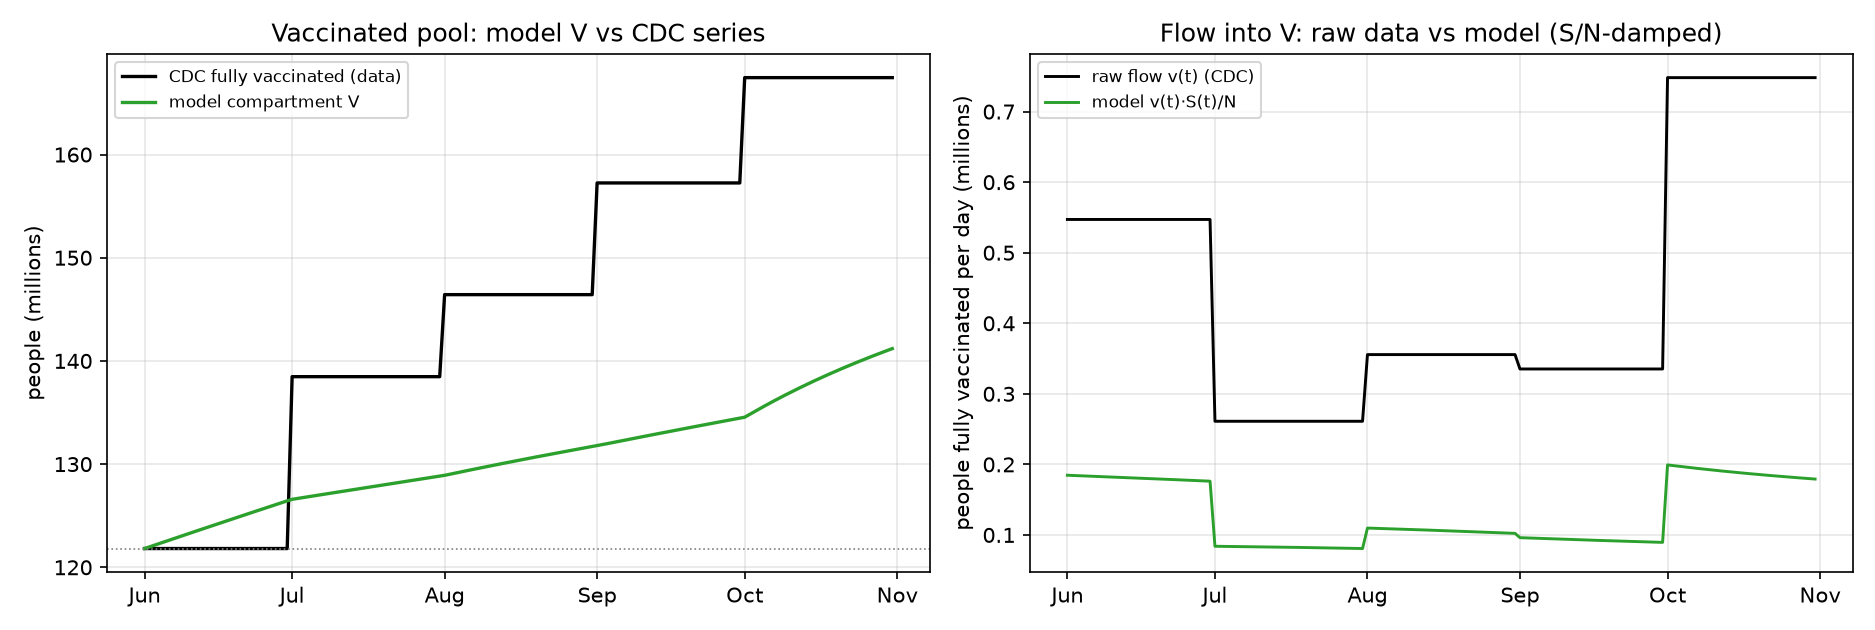

In [3]:
# CDC series on the daily grid: step function — on the 1st of month m the value
# is the month-end cumulative of month m-1 (so 2021-06-01 = 2021-05-31 = V0)
cum_full = cumv.sum(0)
month_vals = {f'{y:04d}-{m:02d}': float(cum_full.loc[f'{y:04d}-{m:02d}']) for y, m in months_full}
V_data = np.zeros(len(dates))
for k, d in enumerate(dates):
    y, m = d.year, d.month
    py, pm = (y - 1, 12) if m == 1 else (y, m - 1)
    V_data[k] = month_vals.get(f'{py:04d}-{pm:02d}', 0.0)

# model effective vaccination flux: v(t) * S(t)/N  (people/day into V)
flux_model = np.zeros(len(dates)); flux_data = np.zeros(len(dates))
for k, d in enumerate(dates):
    mi = months_full.index((d.year, d.month))
    flux_data[k] = flow[:, mi].sum()                                  # raw doses/day
    flux_model[k] = flux_data[k] * Snat[k] / model.N.sum()            # damped by S/N

print('window start V: model %.1fM | CDC %.1fM' % (Vnat[0] / 1e6, V_data[0] / 1e6))
print('window end   V: model %.1fM | CDC %.1fM' % (Vnat[-1] / 1e6, V_data[-1] / 1e6))
print('in-window growth: model +%.1fM | CDC +%.1fM | ratio %.2f'
      % ((Vnat[-1] - Vnat[0]) / 1e6, (V_data[-1] - V_data[0]) / 1e6,
         (Vnat[-1] - Vnat[0]) / max(V_data[-1] - V_data[0], 1)))
print('susceptible share over window: start %.2f -> end %.2f (mean %.2f)'
      % (Snat[0] / model.N.sum(), Snat[-1] / model.N.sum(),
         np.mean(Snat / model.N.sum())))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].plot(dates, V_data / 1e6, lw=1.6, color='k', label='CDC fully vaccinated (data)')
axes[0].plot(dates, Vnat / 1e6, lw=1.6, color='C2', label='model compartment V')
axes[0].axhline(V_data[0] / 1e6, color='grey', ls=':', lw=0.8)
axes[0].set_ylabel('people (millions)')
axes[0].set_title('Vaccinated pool: model V vs CDC series')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(dates, flux_data / 1e6, lw=1.4, color='k', label='raw flow v(t) (CDC)')
axes[1].plot(dates, flux_model / 1e6, lw=1.4, color='C2', label='model v(t)·S(t)/N')
axes[1].set_ylabel('people fully vaccinated per day (millions)')
axes[1].set_title('Flow into V: raw data vs model (S/N-damped)')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig87_appC_v_national.png'); plt.show()
show_fig(f'{ASSETS}/fig87_appC_v_national.png')

## §C.2 Per-state comparison

Same comparison for four representative states (New York, Florida, Texas,
California).  The model's V per state also moves with travellers, but the
national pattern — V₀ exact at the start, slower in-window growth — holds
state by state.

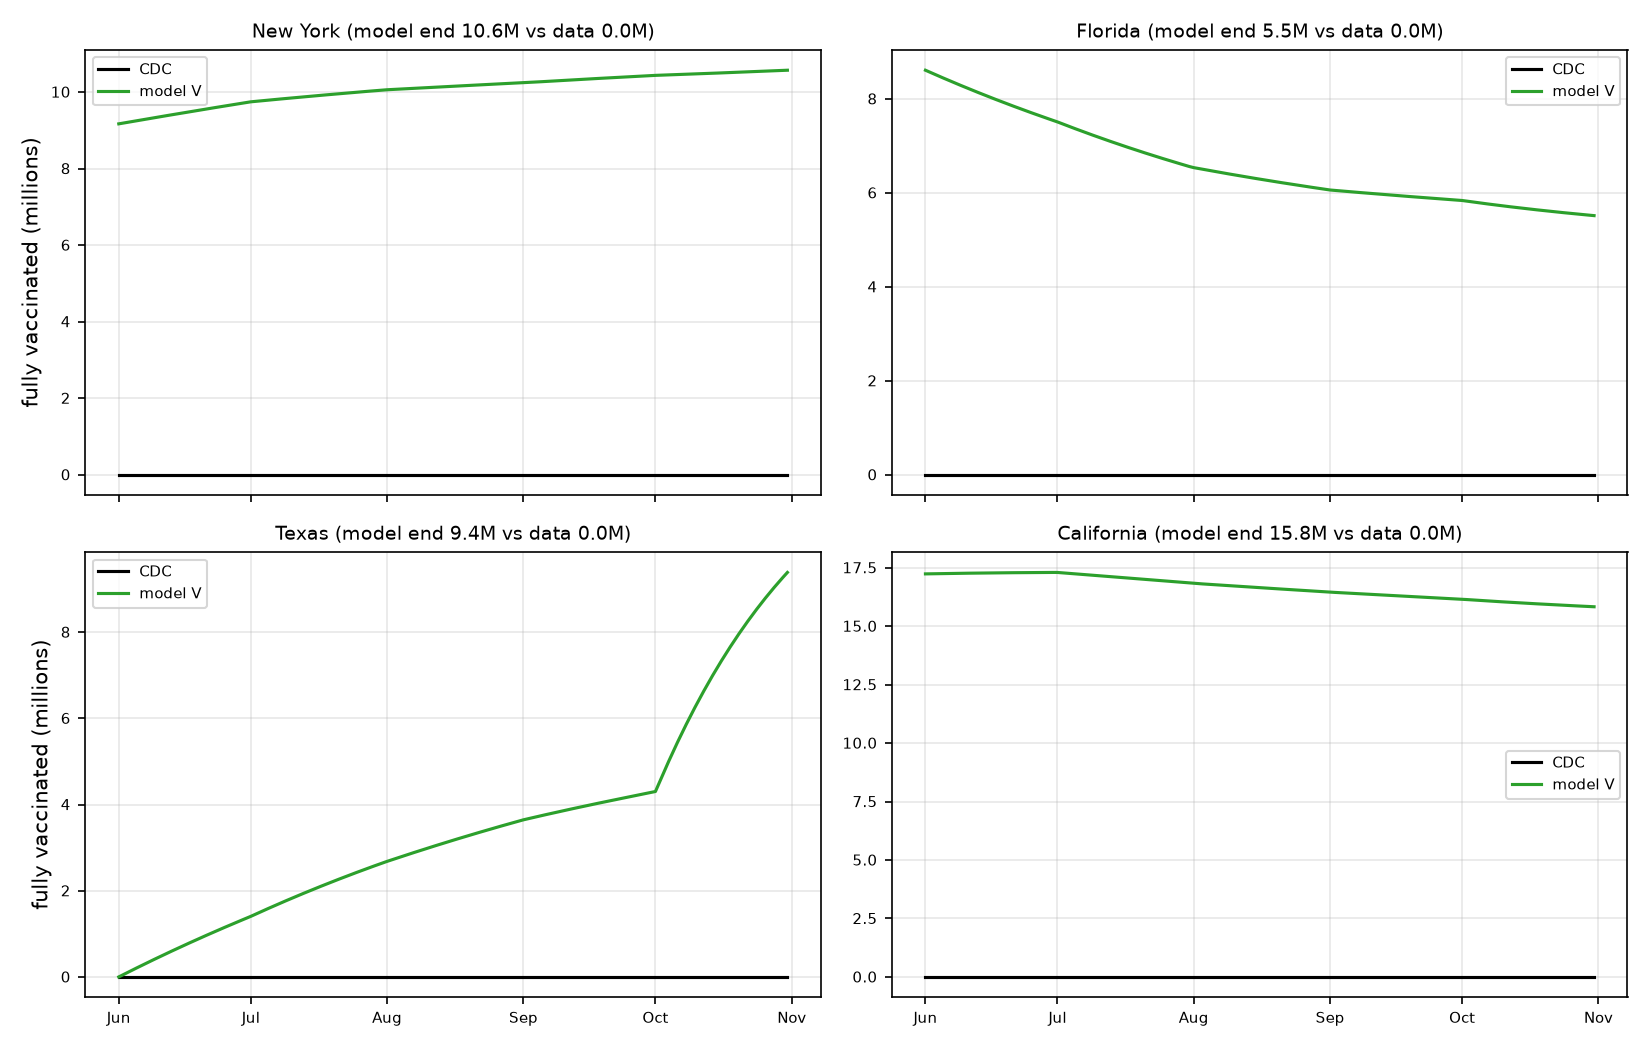

per-state window-end gap (data - model), millions:
  New York       2.4
  Florida        7.3
  Texas          6.1
  California     8.4


In [4]:
sel = ['New York', 'Florida', 'Texas', 'California']
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for axx, name in zip(axes.ravel(), sel):
    code = NAME_TO_CODE[name]
    i = JURISDICTIONS.index(code)
    d_ser = cumv.loc[code]
    Vd = np.interp([(d - DAY0).days for d in dates],
                   [pd.Timestamp(f'{y:04d}-{m:02d}-15').toordinal() for y, m in months_full],
                   [d_ser.loc[f'{y:04d}-{m:02d}'] for y, m in months_full])
    axx.plot(dates, Vd / 1e6, lw=1.5, color='k', label='CDC')
    axx.plot(dates, V[i] / 1e6, lw=1.5, color='C2', label='model V')
    axx.set_title(f'{name} (model end {V[i,-1]/1e6:.1f}M vs data {Vd[-1]/1e6:.1f}M)', fontsize=9)
    axx.tick_params(labelsize=7)
    axx.legend(fontsize=7); axx.grid(alpha=0.3)
    axx.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[0, 0].set_ylabel('fully vaccinated (millions)')
axes[1, 0].set_ylabel('fully vaccinated (millions)')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig88_appC_v_states.png'); plt.show()
show_fig(f'{ASSETS}/fig88_appC_v_states.png')

print('per-state window-end gap (data - model), millions:')
for name in sel:
    code = NAME_TO_CODE[name]
    i = JURISDICTIONS.index(code)
    d_ser = cumv.loc[code]
    Vd_end = float(d_ser['2021-10'])
    print('  %-12s %5.1f' % (name, (Vd_end - V[i, -1]) / 1e6))

## §C.3 Sensitivity: does the in-window vaccination detail matter?

The model's V grows slower than the data because of the $S/N$ damping
(model V +19M in-window vs +60M in the data).  How much does *that*
choice affect the epidemic?  Re-run the identical Delta model with the
raw flow multiplied by f ∈ {1, 3, 10}:

- f = 1: the current treatment (only susceptibles vaccinated);
- f = 3: ≈ all actual doses land in V (cancels the initial damping,
  S/N ≈ 1/3) — this makes the model's V match the CDC curve;
- f = 10: a stress test — more people "vaccinated" than the real supply
  allows (unphysical).

 flow_factor   pi_hat       peak    R2_log
           1 1.100398 2021-09-02  0.915850
           3 0.628247 2021-08-31  0.756830
          10 0.127878 2021-07-25 -1.170375


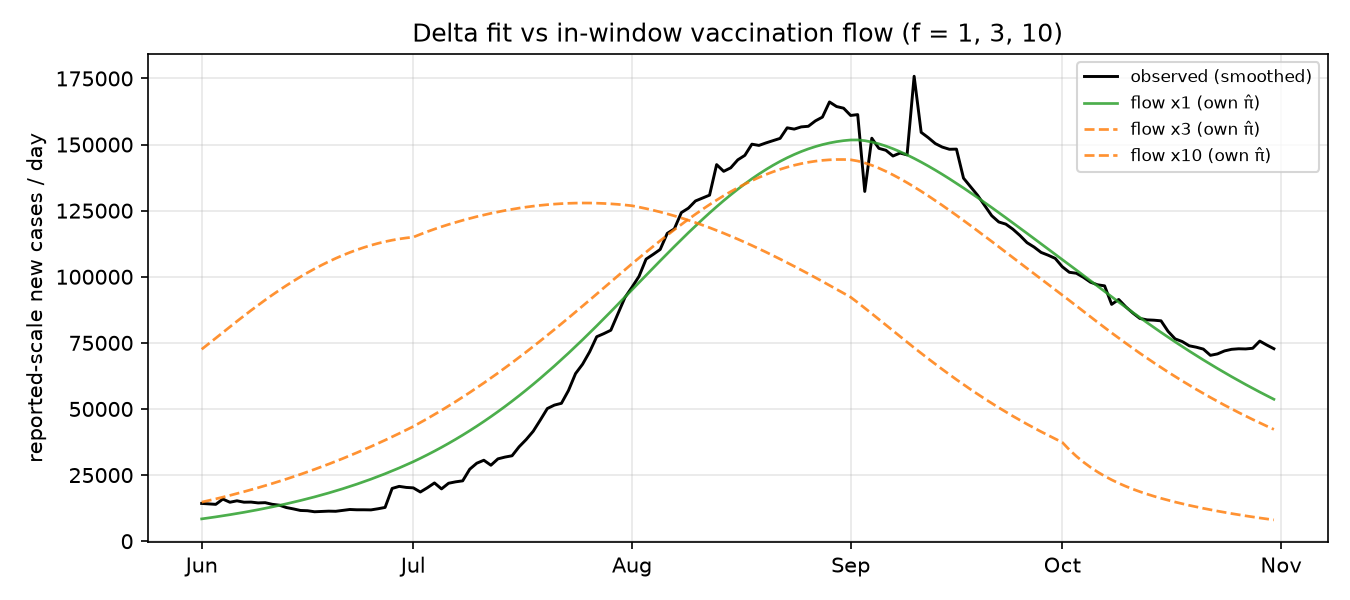

In [5]:
nat_obs_all = us.groupby('date')['new_cases_smooth'].sum()
nat_obs = nat_obs_all.reindex(dates).fillna(0).values

def run_flow_factor(f):
    m = FusedMetapopulationSEIR(
        JURISDICTIONS, CENSUS_POPULATIONS, W_cal, mu0, s_func,
        k_vals, P_k, beta=beta_v, sigma=sigma, gamma=gamma,
        months=months_full, vac_flow=flow * f, vac_efficacy=eps, V0_dict=V0,
        R_init_dict=R0init, beta_scale=g2)
    m.simulate(TMAX, I0, E0, t0=T0)
    ni = m.daily_new_infections().sum(0)
    ph = ni.sum() / nat_obs.sum()
    r2l = 1 - np.sum((np.log(ni / ph + 1) - np.log(nat_obs + 1)) ** 2) / np.sum((np.log(nat_obs + 1) - np.log(nat_obs + 1).mean()) ** 2)
    return ni, ph, int(np.argmax(ni)), r2l

rows = []
curves = {}
for f in (1, 3, 10):
    ni, ph, pk, r2l = run_flow_factor(f)
    curves[f] = (ni, ph)
    rows.append((f, ph, dates[pk].date(), r2l))
sens = pd.DataFrame(rows, columns=['flow_factor', 'pi_hat', 'peak', 'R2_log'])
print(sens.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(dates, nat_obs, lw=1.4, color='k', label='observed (smoothed)')
for f in (1, 3, 10):
    ni, ph = curves[f]
    ax.plot(dates, ni / ph, lw=1.3, ls='--' if f != 1 else '-',
            color='C2' if f == 1 else 'C1', alpha=0.85,
            label=f'flow x{f} (own π̂)')
ax.set_ylabel('reported-scale new cases / day')
ax.set_title('Delta fit vs in-window vaccination flow (f = 1, 3, 10)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig89_appC_sensitivity.png'); plt.show()
show_fig(f'{ASSETS}/fig89_appC_sensitivity.png')

## §C.4 Honest reading

**What the comparison shows**

- **V₀ matches the data exactly by construction** (ε = 1, cumulative
  fully-vaccinated at 2021-05-31 placed in V).
- **In-window, the model's V grows ≈ 2–3× slower than the CDC series**
  (model +19M vs data ≈ +46M, ratio 0.42 — the flow-weighted susceptible
  share): the model only
  vaccinates the susceptible fraction, while the data counts every newly
  fully-vaccinated person — including previously infected people, who sit
  in R, not S, in the model.  This is the intended semantics (V is the
  *protected susceptible* pool, not a vaccination-certificate counter),
  but it means **the model's V is not directly comparable to the CDC
  cumulative series** — only its susceptible-protection share is.

**The vaccination-flow treatment is NOT neutral (§C.3)**

- f = 1 → 3 moves π̂ from 1.10 to 0.63 and R²(log) from 0.92 to 0.76: if
  *all* actual doses landed in V (matching the CDC curve), the model would
  over-deplete the susceptible pool and under-produce the wave.
- f = 10 (unphysical: more vaccinated than the supply allows) empties S
  within weeks (peak 2021-07-25, π̂ 0.13).
- Interpretation: the current ε = 1.0 / asc = 3.0 parameters partially
  **compensate** for the f = 1 damping — the immune-pool treatment
  (V₀, flow scaling, ε, asc) is one coupled choice, not four independent
  ones.  A joint fit over (flow treatment, ε, asc) is the honest next
  step; until then π̂ ≈ 1.10 should be read as "consistent with the
  chosen immune-pool parameterisation", not as a uniquely determined
  reporting ratio.

**Caveats**

1. **Double counting**: in reality some of the ~100M "prior infections"
   were later vaccinated; placing them in both R (prior immunity, asc = 3)
   and V (V₀ = full cumulative) overstates the immune pool.
2. **ε = 1** (full protection) and **no waning** are idealisations; both
   are documented open items.
3. The per-state gaps vary with vaccination speed (states that vaccinated
   late in the window show larger data-model gaps).

In [6]:
print('appendix C complete | figures fig87, fig88, fig89 -> assets/')

appendix C complete | figures fig87, fig88, fig89 -> assets/
